### Imports

In [1]:
# === Library Imports ===

# Standard Libraries
import os
import warnings
import logging
from datetime import datetime
from dataclasses import dataclass, field
import joblib

# Data Handling
import pandas as pd
import numpy as np
from openpyxl import Workbook
from openpyxl.styles import PatternFill, Alignment

# Machine Learning
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import boxcox

# Models
import lightgbm as lgb
from catboost import CatBoostRegressor, Pool

# Visualization
import matplotlib.pyplot as plt
import shap

# Utilities
from sqlalchemy import create_engine
from urllib.parse import quote_plus

# Custom Utilities
import utils.prediction_utils as pred
from utils import dictionaries as dictionary
# from utils.logger import setup_logger

# === Jupyter Notebook Configuration ===
from IPython.core.interactiveshell import InteractiveShell

# Enable IPython to display all outputs for each cell
InteractiveShell.ast_node_interactivity = "all"

# === Warnings and Logging Configuration ===

# Suppress warnings
warnings.filterwarnings('ignore')
warnings.filterwarnings("ignore", category=UserWarning, module='lightgbm')

# Set logging for matplotlib and custom logger
plt.set_loglevel('warning')
logger = logging.getLogger("MyLogger")

# === Pandas Display Configuration ===
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

### Class definition

In [2]:
TRAIN_END_DATE = '2023-08-01'
VAL_END_DATE = '2024-09-30'
TEST_START_DATE = '2024-10-01'

TARGET = 'ster_1+_total'
TARGET_GROUP = '25-67'

NUMERICAL_COLS = ['npo1_grp_daynight', 'npo1_grp_primetime',
                  'npo2_grp_daynight', 'npo2_grp_primetime',
                  'npo3_grp_daynight', 'npo3_grp_primetime',
                  'regio_grp_daynight', 'regio_grp_primetime',
                  'timef_olympic_period_overlap', 'timef_football_period_overlap',
                  'timef_duration_days',
                  # 'timef_start_month', 'timef_end_month',
                  'timef_start_year',
                  # 'timef_end_year',
                  'timef_start_week',
                  # 'timef_end_week',
                  # 'timef_end_day',
                  # 'timef_start_day'
                ]

CATEGORICAL_COLS = [
                    # 'timef_start_season',
                    # 'timef_end_season'
                    ]

BOOLEAN_COLS = [
                'alcohol_kansspelen',
                'is_olympic_period',
                'is_football_period',
                # 'new_data'
                ]

FEATURES = NUMERICAL_COLS + CATEGORICAL_COLS + BOOLEAN_COLS

In [ ]:
@dataclass
class ModelTrainer:
    # Input and configuration
    df: pd.DataFrame = None
    target: str = TARGET
    features: list = field(default_factory=lambda: FEATURES)
    train_end_date: str = TRAIN_END_DATE
    val_end_date: str = VAL_END_DATE
    test_start_date: str = TEST_START_DATE
    target_group: str = TARGET_GROUP
    numerical_cols: list = field(default_factory=lambda: NUMERICAL_COLS)
    categorical_cols: list = field(default_factory=lambda: CATEGORICAL_COLS)
    boolean_cols: list = field(default_factory=lambda: BOOLEAN_COLS)

    # Default LightGBM parameters
    params: dict = field(default_factory=lambda: {
        "objective": "regression",
        "metric": "rmse",
        "boosting_type": "gbdt",
        "learning_rate": 0.01,
        "num_leaves": 41,
        "max_depth": 8,
        "subsample": 0.5,
        "colsample_bytree": 1.0,
        "reg_alpha": 1.5,
        "reg_lambda": 2,
        "max_bin": 512,
        "n_estimators": 200,
        "verbose": 1,
        "seed": 42,
    })

    # Preprocessor and model setup
    encoder: OneHotEncoder = field(default_factory=lambda: OneHotEncoder(drop="first", sparse_output=False))
    preprocessor: object = None
    feature_names: list = field(default_factory=list)
    model: lgb.LGBMRegressor = field(init=False)
    best_params: dict = field(init=False, default_factory=dict)

    train_data: pd.DataFrame = field(init=False)
    val_data: pd.DataFrame = field(init=False)
    test_data: pd.DataFrame = field(init=False)

    # Train-test split data
    X_train: np.ndarray = field(init=False)
    X_val: np.ndarray = field(init=False)
    y_train: np.ndarray = field(init=False)
    y_val: np.ndarray = field(init=False)
    X_test: np.ndarray = field(init=False)
    y_test: np.ndarray = field(init=False)

    def __post_init__(self):
        if self.df is None:
            query = self.construct_query()
            self.df = self.query_to_df(query)
            self.df = self.prep_dataframe(self.df)
        self.create_preprocessor()
        self.model = self.initialize_model()

    def initialize_model(self):
        """
        Initialize the LightGBM model with the predefined parameters.

        Returns:
            lgb.LGBMRegressor: A LightGBM model instance.
        """
        return lgb.LGBMRegressor(
            objective=self.params.get("objective", "regression"),
            metric=self.params.get("metric", "rmse"),
            boosting_type=self.params.get("boosting_type", "gbdt"),
            learning_rate=self.params.get("learning_rate", 0.01),
            num_leaves=self.params.get("num_leaves", 31),
            max_depth=self.params.get("max_depth", -1),
            subsample=self.params.get("subsample", 1.0),
            colsample_bytree=self.params.get("colsample_bytree", 1.0),
            reg_alpha=self.params.get("reg_alpha", 0.0),
            reg_lambda=self.params.get("reg_lambda", 1.0),
            max_bin=self.params.get("max_bin", 255),
            n_estimators=self.params.get("n_estimators", 100),
            drop_rate=self.params.get("drop_rate", 0.0),
            min_split_gain=self.params.get("min_split_gain", 0.0),
            subsample_freq=self.params.get("subsample_freq", 0),
            verbose=self.params.get("verbose", -1),
            random_state=self.params.get("seed", 42),
        )

    def construct_query(self):
        if isinstance(self.target_group, (list, tuple)):
            target_group_str = ', '.join([f"'{tg}'" for tg in self.target_group])
        else:
            target_group_str = f"'{self.target_group}'"

        query = f'''
            SELECT b.flight_id,
                   b.target_group,
                   f.advertiser,
                   f.product,
                   f.start_date,
                   f.end_date,
                   b.campaign_duration,
                   b.daypart,
                   f.mock_campaign,
                   f.alcohol_kansspelen,
                   b.ster_grp,
                   b.regio_grp,
                   b.npo1_grp,
                   b.npo2_grp,
                   b.npo3_grp,
                   b.[ster_1+]
            FROM [dbo].[tv.bereik_ster] b
            LEFT JOIN [dbo].[tv.flights_ster] f ON b.flight_id = f.flight_id
            WHERE b.ster_grp > 0
            AND target_group IN ({target_group_str})
            AND b.campaign_duration > 7
            --AND NOT (YEAR(start_date) = 2024 AND MONTH(start_date) IN (6, 7, 8))
            ORDER BY start_date;
        '''
        return query

    def create_sql_alchemy_engine(self):
        """
        Creates and returns a SQLAlchemy engine for connecting to a SQL Server database.
        """
        quoted = quote_plus(
            "Driver={ODBC+Driver+17+for+SQL+Server};"
            "Server=tcp:stercampsql.database.windows.net;"
            "Database=SterCampNew;"
            "uid=stercampadmin;"
            f"pwd={os.getenv('SQLDB')}"
        )
        alchemy_con = f"mssql+pyodbc:///?odbc_connect={quoted}"
        engine = create_engine(alchemy_con)
        return engine

    def query_to_df(self, query):
        engine = self.create_sql_alchemy_engine()
        df_query = pd.read_sql_query(query, engine)
        return df_query

    def prep_dataframe(self, df):
        df = df[["flight_id", "target_group", "start_date", "end_date", "advertiser", "product", "daypart", "mock_campaign", "alcohol_kansspelen",
                        "npo1_grp", "npo2_grp", "npo3_grp", "regio_grp", "ster_grp",
                        "ster_1+"]].reset_index(drop=True)

        df = (df.pivot_table(index=["flight_id", "target_group", "start_date", "end_date", 'advertiser', 'product', "mock_campaign", "alcohol_kansspelen"],
                            columns='daypart', fill_value=0.0,
                            values=['npo1_grp', 'npo2_grp', 'npo3_grp',
                                    'ster_grp', 'ster_1+', 'regio_grp'], aggfunc='sum').reset_index())


        df.columns = ["_".join(col) if col[1] else col[0] for col in df.columns.to_flat_index()]

        # Convert start_date and end_date to datetime objects and calculate required values
        df['start_date'] = pd.to_datetime(df['start_date'], format="%d%m%y", errors='coerce')
        df['end_date'] = pd.to_datetime(df['end_date'], format="%d%m%y", errors='coerce')

        # Apply function to create extra columns
        df['timef_start_month'] = df['start_date'].dt.month
        df['timef_end_month'] = df['end_date'].dt.month
        df['timef_start_year'] = df['start_date'].dt.year
        df['timef_end_year'] = df['end_date'].dt.year
        df['timef_start_week'] = df['start_date'].dt.strftime("%V").astype(int)
        df['timef_end_week'] = df['end_date'].dt.strftime("%V").astype(int)
        df['timef_start_day'] = df['start_date'].dt.day
        df['timef_end_day'] = df['end_date'].dt.day
        df['timef_duration_days'] = df.apply(lambda row: (row['end_date'] - row['start_date']).days + 1, axis=1)

        df['timef_start_season'] = df['timef_start_month'].apply(lambda month: 'Winter' if month in [12, 1, 2] else
                                                      'Spring' if month in [3, 4, 5] else
                                                      'Summer' if month in [6, 7, 8] else
                                                      'Autumn')
        df['timef_end_season'] = df['timef_end_month'].apply(lambda month: 'Winter' if month in [12, 1, 2] else
                                                    'Spring' if month in [3, 4, 5] else
                                                    'Summer' if month in [6, 7, 8] else
                                                    'Autumn')

        # Calculate total overlap with olympics and WK/EK
        df['timef_olympic_period_overlap'] = df.apply(pred.calculate_total_overlap, axis=1, period_list=(dictionary.olympic_period_list))
        df['timef_football_period_overlap'] = df.apply(pred.calculate_total_overlap, axis=1, period_list=(dictionary.football_wk_ek_list))

        # Create interaction features
        df['grp_olympic_overlap'] = df['ster_grp_total'] * df['timef_olympic_period_overlap']
        df['grp_football_overlap'] = df['ster_grp_total'] * df['timef_football_period_overlap']

        # Create binary indicators
        df['is_olympic_period'] = (df['timef_olympic_period_overlap'] > 0).astype(int)
        df['is_football_period'] = (df['timef_football_period_overlap'] > 0).astype(int)

        # Create a new column 'new_data' indicating old or new
            # df['new_data'] = pd.cut(
            #     df['start_date'],
            #     bins=[pd.Timestamp.min, pd.to_datetime('2023-09-01'), pd.Timestamp.max],
            #     labels=[0, 1])

        # Add n random rows that have a base value of 0 GRPs and bereik
        non_grp_columns = ['start_date', 'end_date', 'timef_duration_days', 'timef_olympic_period_overlap', 'timef_football_period_overlap',
                            'timef_start_day', 'timef_end_day', 'timef_start_week', 'timef_end_week', 'timef_start_month',
                            'timef_end_month', 'timef_start_year', 'timef_end_year', 'timef_start_season', 'timef_end_season',
                            'target_group', 'advertiser', 'product', 'mock_campaign', 'alcohol_kansspelen', 'new_data']

        # Sample 600 random rows with 0 GRPs and bereik
        sampled_df = df.sample(n=600, random_state=42).reset_index(drop=True)
        sampled_df_zeroed = sampled_df.copy()
        for column in sampled_df_zeroed.columns:
            if column not in non_grp_columns:
                sampled_df_zeroed[column] = 0

        df_combined = pd.concat([df, sampled_df_zeroed], ignore_index=True)

        df = df_combined.sort_values(by=['start_date', 'advertiser', 'product', 'end_date'])

        def shift_to_positive(column):
            if column.min() <= 0:
                return column + abs(column.min()) + 1
            return column

        # # Ensure positive values
        # df["npo3_grp_daynight"] = shift_to_positive(df["npo3_grp_daynight"])
        # df["npo3_grp_primetime"] = shift_to_positive(df["npo3_grp_primetime"])

        # # Apply Box-Cox transformation
        # transformed_data_daynight, lambda_value = boxcox(df["npo3_grp_daynight"])
        # transformed_data_primetime, lambda_value = boxcox(df["npo3_grp_primetime"])

        # # Store the transformed column and lambda
        # df["npo3_grp_daynight"] = transformed_data_daynight
        # df["npo3_grp_primetime"] = transformed_data_primetime

        ########## Filter Outliers ##########

        q_low = df['ster_grp_total'].quantile(0.01)
        q_hi  = df['ster_grp_total'].quantile(0.99)
        df = df[(df['ster_grp_total'] < q_hi) & (df['ster_grp_total'] > q_low)]

        q_low = df['ster_1+_total'].quantile(0.01)
        q_hi  = df['ster_1+_total'].quantile(0.99)
        df = df[(df['ster_1+_total'] < q_hi) & (df['ster_1+_total'] > q_low)]

        ##############################################

        return df

    def create_preprocessor(self):
        transformers = []

        numerical_transformer_steps = [('imputer', SimpleImputer(strategy='mean'))]
        numerical_transformer = Pipeline(steps=numerical_transformer_steps)
        transformers.append(('num', numerical_transformer, self.numerical_cols))

        if self.categorical_cols:
            categorical_transformer = Pipeline(steps=[
                ('imputer', SimpleImputer(strategy='most_frequent')),
                ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first'))])
            transformers.append(('cat', categorical_transformer, self.categorical_cols))

        if self.boolean_cols:
            boolean_transformer = Pipeline(steps=[
                ('int_conversion', FunctionTransformer(lambda x: x.astype(int), validate=False)),
                ('imputer', SimpleImputer(strategy='most_frequent'))])
            transformers.append(('bool', boolean_transformer, self.boolean_cols))

        self.preprocessor = ColumnTransformer(transformers=transformers)

    def get_feature_names(self, preprocessor):
        feature_names = []

        # Get numerical feature names
        if 'num' in preprocessor.named_transformers_:
            feature_names += self.numerical_cols

        # Get categorical feature names
        if 'cat' in preprocessor.named_transformers_:
            encoder = preprocessor.named_transformers_['cat'].named_steps['onehot']
            cat_feature_names = encoder.get_feature_names_out(self.categorical_cols)
            feature_names += cat_feature_names.tolist()

        # Get boolean feature names
        if 'bool' in preprocessor.named_transformers_:
            feature_names += self.boolean_cols

        self.feature_names = feature_names

        return feature_names

    def split_and_preprocess(self):
        """
        Splits the data by date ranges, fits the preprocessor, and transforms all datasets.

        Parameters:
        - df (DataFrame): Full dataset to split and preprocess.
        - train_end_date (str): End date for the training set.
        - val_end_date (str): End date for the validation set.
        - test_start_date (str): Start date for the test set.
        """
        df = self.df.copy()
        # Ensure 'start_date' is datetime
        df['start_date'] = pd.to_datetime(df['start_date'])

        # Split data
        self.train_data = df[df['start_date'] < pd.Timestamp(self.train_end_date)]
        self.val_data = df[(df['start_date'] >= pd.Timestamp(self.train_end_date)) &
                        (df['start_date'] <= pd.Timestamp(self.val_end_date))]
        self.test_data = df[df['start_date'] >= pd.Timestamp(self.test_start_date)]

        print(f"Train date range: {self.train_data['start_date'].min()} - {self.train_data['start_date'].max()}")
        print(f"Validation date range: {self.val_data['start_date'].min()} - {self.val_data['start_date'].max()}")
        print(f"Test date range: {self.test_data['start_date'].min()} - {self.test_data['start_date'].max()}")

        # Fit and transform the datasets
        self.fit_and_transform_data()

    def fit_and_transform_data(self):
        """
        Fits the preprocessor on the training data and transforms all datasets (train, val, test).
        """
        print("Fitting preprocessor on training data...")
        self.preprocessor.fit(self.train_data[self.features])

        print("Extracting feature names...")
        self.feature_names = self.get_feature_names(self.preprocessor)

        print("Transforming datasets...")
        self.X_train, self.y_train = self._transform(self.train_data)
        self.X_val, self.y_val = self._transform(self.val_data)
        self.X_test, self.y_test = self._transform(self.test_data)

    def _transform(self, data):
        """
        Transforms the given dataset using the pre-fitted preprocessor.

        Parameters:
        - data (DataFrame): Dataset to transform.

        Returns:
        - X_transformed, y: Transformed feature matrix and target array.
        """
        print(f"Transforming data with shape: {data.shape}")
        X = data[self.features]
        y = data[self.target].values.reshape(-1, 1)
        X_transformed = self.preprocessor.transform(X)
        return np.array(X_transformed), y

    def tune_hyperparameters_with_randomized_search(self, data, y, n_iter=3, n_splits=3, scoring='neg_root_mean_squared_error'):
        """
        Tune hyperparameters using RandomizedSearchCV with a time series split.

        Args:
            data (np.ndarray): Feature matrix.
            y (np.ndarray): Target array.
            n_iter (int): Number of random parameter combinations to try.
            n_splits (int): Number of splits for TimeSeriesSplit cross-validation.
            scoring (str): Scoring metric for evaluation.

        Returns:
            dict: Best hyperparameters found during the search.
        """
        from time import time

        # TimeSeriesSplit for cross-validation
        tscv = TimeSeriesSplit(n_splits=n_splits)

        # Parameter grid for random search
        param_grid = {
            'boosting_type': ['dart', 'gbdt'],
            'learning_rate': [0.005, 0.01, 0.03, 0.05],
            'num_leaves': [30, 40, 45, 50],
            'max_depth': [5, 6, 7, 8, 12],
            'subsample': [0.6, 0.8, 0.9, 1.0],  # Use subsample instead of bagging_fraction
            'colsample_bytree': [0.8, 0.9, 1.0],  # Keep colsample_bytree
            'reg_alpha': [0.0, 0.5, 1.0, 1.5],
            'reg_lambda': [0.5, 1.0, 1.5, 2],
            'max_bin': [300, 400, 512, 1024],
            'n_estimators': [500, 1000, 1200, 1500],
            'min_data_in_leaf': [3, 8, 10, 12],  # Remove min_child_samples
            'min_split_gain': [0.05, 0.1, 0.2],
            'min_child_weight': [1, 5, 10],
            'path_smooth': [0.0, 0.1, 0.2],
            'metric': ['rmse'],
        }

        # Initialize LightGBM model
        # model = lgb.LGBMRegressor()

        # Initialize RandomizedSearchCV
        randomized_search = RandomizedSearchCV(
            estimator=self.model,
            param_distributions=param_grid,
            n_iter=n_iter,
            scoring=scoring,
            cv=tscv,
            verbose=1,
            n_jobs=-1,
            random_state=42
        )

        print("Starting hyperparameter tuning...")
        start_time = time()

        # Perform hyperparameter tuning
        randomized_search.fit(data, y,
                              feature_name=self.feature_names,
                              eval_set=[(self.X_val, self.y_val)],
                              eval_metric='rmse',
                              )

        end_time = time()
        elapsed_time = end_time - start_time
        print(f"Hyperparameter tuning completed in {elapsed_time:.2f} seconds.")

        # Retrieve best parameters and best score
        self.best_params = randomized_search.best_params_
        self.model = randomized_search.best_estimator_

        print(f"Best Parameters: {self.best_params}")
        print(f"Best Score: {randomized_search.best_score_}")

        return {
            "best_params": randomized_search.best_params_,
            "best_score": randomized_search.best_score_,
            "elapsed_time": elapsed_time
        }

    def train_and_analyze(self):
        # Remove scikit-learn-specific parameters
        params = self.best_params.copy()

        # Convert training and validation data to LightGBM datasets
        train_data = lgb.Dataset(self.X_train, label=self.y_train)
        val_data = lgb.Dataset(self.X_val, label=self.y_val, reference=train_data)

        # Use a dictionary to capture evaluation results via a callback
        evals_result = {}

        def record_evals_result(env):
            """Custom callback to record evaluation results."""
            for data_name, eval_name, result, _ in env.evaluation_result_list:
                if data_name not in evals_result:
                    evals_result[data_name] = {}
                if eval_name not in evals_result[data_name]:
                    evals_result[data_name][eval_name] = []
                evals_result[data_name][eval_name].append(result)

        print("Starting model training...")

        # Train the model with the LightGBM >= 4.0.0 approach
        self.model = lgb.train(
            params=params,
            train_set=train_data,
            valid_sets=[val_data],  # Pass only the validation set for evaluation
            num_boost_round=3000,  # Maximum number of boosting iterations
            callbacks=[
                lgb.early_stopping(stopping_rounds=200),  # Early stopping callback
                lgb.log_evaluation(period=100),  # Log evaluation metrics every 100 iterations
                record_evals_result  # Custom callback to record evaluation results
            ]
        )

        print("\nModel training completed.")
        print(f"Best iteration: {self.model.best_iteration}")
        print(f"Best score on validation set: {self.model.best_score['rmse']}")

        # Plot evaluation results
        self.plot_learning_curve(evals_result)
        self.best_model = self.model

    def plot_learning_curve(self, evals_result):
        """
        Plot learning curves from evaluation results.

        Inputs:
        - evals_result: Dictionary of evaluation results.
        """
        # Check if 'rmse' is in evaluation results
        if 'valid_0' in evals_result and 'rmse' in evals_result['valid_0']:
            plt.figure(figsize=(10, 6))
            plt.plot(evals_result['valid_0']['rmse'], label='Validation RMSE', marker='o')
            plt.title('Learning Curve (RMSE)')
            plt.xlabel('Iterations')
            plt.ylabel('RMSE')
            plt.legend()
            plt.grid(True)  # Add grid for better visualization

            # Save plot to a file (optional)
            plt.savefig("learning_curve.png", dpi=300)

            # Ensure the plot is displayed
            plt.show()

    def display_metrics(self, y_train_true, y_train_pred, y_val_true, y_val_pred):
        """
        Display regression metrics (MAE, MSE, RMSE, R²) for both training and validation sets.

        Parameters:
        - y_train_true (array-like): True target values for the training set.
        - y_train_pred (array-like): Predicted target values for the training set.
        - y_val_true (array-like): True target values for the validation set.
        - y_val_pred (array-like): Predicted target values for the validation set.

        Returns:
        None (prints metrics directly)
        """
        # Training Metrics
        train_mae = mean_absolute_error(y_train_true, y_train_pred)
        train_mse = mean_squared_error(y_train_true, y_train_pred)
        train_rmse = np.sqrt(train_mse)
        train_r2 = r2_score(y_train_true, y_train_pred)

        # Validation Metrics
        val_mae = mean_absolute_error(y_val_true, y_val_pred)
        val_mse = mean_squared_error(y_val_true, y_val_pred)
        val_rmse = np.sqrt(val_mse)
        val_r2 = r2_score(y_val_true, y_val_pred)

        # Display Metrics
        print("Training Set Metrics:")
        print(f"  MAE: {train_mae:.4f}")
        print(f"  MSE: {train_mse:.4f}")
        print(f"  RMSE: {train_rmse:.4f}")
        print(f"  R²: {train_r2:.4f}")

        print("\nValidation Set Metrics:")
        print(f"  MAE: {val_mae:.4f}")
        print(f"  MSE: {val_mse:.4f}")
        print(f"  RMSE: {val_rmse:.4f}")
        print(f"  R²: {val_r2:.4f}")

    def extract_and_visualize_shap_values(self, feature_dependence = 'timef_duration_days'):
        if self.model is None:
            print("No best model found. Please run grid_search_models first.")
            return

        explainer = shap.TreeExplainer(self.model)
        shap_values = explainer.shap_values(self.X_train)

        # Check SHAP summary plot
        shap.summary_plot(shap_values, self.X_train, feature_names=model.feature_names)

        # Analyze specific features
        shap.dependence_plot(feature_dependence, shap_values, self.X_train, feature_names=model.feature_names)

    def predict_and_export_to_excel(self, file_path="test_predictions.xlsx"):
        """
        Predicts on self.test_data and exports the results, including target, prediction, and residuals, to an Excel file.

        Parameters:
        - file_path (str): The path to save the Excel file. Default is "test_predictions.xlsx".
        """
        print("Using:", type(self.model))

        # Ensure the model and data are available
        if not hasattr(self, "model") or self.model is None:
            raise ValueError("The model is not trained. Train the model before making predictions.")
        if not hasattr(self, "X_test") or self.X_test is None:
            raise ValueError("Test data is not available.")

        df_test = self.test_data.copy()

        # Predict on the test set
        predictions = self.model.predict(self.X_test)

        # Add predictions and residuals to the test dataframe
        df_test["prediction_lgb"] = predictions
        df_test[self.target] = self.y_test.flatten()
        df_test["residual_lgb"] = df_test[self.target] - df_test["prediction_lgb"]

        # Round the numerical values for better readability
        df_test[["prediction_lgb", self.target, "residual_lgb"]] = df_test[["prediction_lgb", self.target, "residual_lgb"]].round(2)

        # Select relevant columns
        df_test = df_test[[
            'flight_id', 'target_group', 'start_date', 'end_date', 'timef_duration_days', 'advertiser',
            'product', 'alcohol_kansspelen', 'npo1_grp_daynight',
            'npo1_grp_primetime', 'npo1_grp_total', 'npo2_grp_daynight',
            'npo2_grp_primetime', 'npo2_grp_total', 'npo3_grp_daynight',
            'npo3_grp_primetime', 'npo3_grp_total', 'regio_grp_daynight',
            'regio_grp_primetime', 'regio_grp_total', 'ster_grp_total',
            'ster_1+_total', 'prediction_lgb', 'residual_lgb'
        ]]

        # Calculate metrics
        test_mae = mean_absolute_error(self.y_test, predictions)
        test_mse = mean_squared_error(self.y_test, predictions)
        test_rmse = np.sqrt(test_mse)
        test_r2 = r2_score(self.y_test, predictions)

        # Display Metrics
        print("Test Set Metrics:")
        print(f"  MAE: {test_mae:.4f}")
        print(f"  MSE: {test_mse:.4f}")
        print(f"  RMSE: {test_rmse:.4f}")
        print(f"  R²: {test_r2:.4f}")

        df_test.to_excel(file_path, index = False)

    def predict_single_df(self, df):

        # Convert start_date and end_date to datetime objects and calculate required values
        df['start_date'] = pd.to_datetime(df['start_date'], format="%d%m%y", errors='coerce')
        df['end_date'] = pd.to_datetime(df['end_date'], format="%d%m%y", errors='coerce')

        # Apply function to create extra columns
        df['timef_start_month'] = df['start_date'].dt.month
        df['timef_end_month'] = df['end_date'].dt.month
        df['timef_start_year'] = df['start_date'].dt.year
        df['timef_end_year'] = df['end_date'].dt.year
        df['timef_start_week'] = df['start_date'].dt.strftime("%V").astype(int)
        df['timef_end_week'] = df['end_date'].dt.strftime("%V").astype(int)
        df['timef_start_day'] = df['start_date'].dt.day
        df['timef_end_day'] = df['end_date'].dt.day
        df['timef_duration_days'] = df.apply(lambda row: (row['end_date'] - row['start_date']).days + 1, axis=1)

        df['timef_start_season'] = df['timef_start_month'].apply(lambda month: 'Winter' if month in [12, 1, 2] else
                                                      'Spring' if month in [3, 4, 5] else
                                                      'Summer' if month in [6, 7, 8] else
                                                      'Autumn')
        df['timef_end_season'] = df['timef_end_month'].apply(lambda month: 'Winter' if month in [12, 1, 2] else
                                                    'Spring' if month in [3, 4, 5] else
                                                    'Summer' if month in [6, 7, 8] else
                                                    'Autumn')

        # Calculate total overlap with olympics and WK/EK
        df['timef_olympic_period_overlap'] = df.apply(pred.calculate_total_overlap, axis=1, period_list=(dictionary.olympic_period_list))
        df['timef_football_period_overlap'] = df.apply(pred.calculate_total_overlap, axis=1, period_list=(dictionary.football_wk_ek_list))

        # Create a new column 'new_data' indicating old or new
        df['new_data'] = pd.cut(
            df['start_date'],
            bins=[pd.Timestamp.min, pd.to_datetime('2023-09-01'), pd.Timestamp.max],
            labels=[0, 1])

        X_new = df[self.features].copy()

        # Preprocess the new data using the same preprocessor used in the best model
        X_preprocessed = self.preprocessor.transform(X_new)

        # Predict using the best model
        df["prediction"] = self.model.predict(X_preprocessed)

        df[self.target] = self.y_test.flatten()
        df["residual"] = df[self.target] - df["prediction"]

        # Round the numerical values for better readability
        df[["prediction", self.target, "residual"]] = df[["prediction", self.target, "residual"]].round(2)

        return predictions

    def create_visualizations(df, file_name):
        # Maak vier subplots
        fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(10, 8))

        # # Scatterplot Werkelijk vs. Voorspeld Bereik
        axes[0, 0].scatter(df["ster_1bereik_total"], df['predictions'])
        axes[0, 0].set_xlabel('Werkelijk Bereik')
        axes[0, 0].set_ylabel('Voorspeld Bereik')
        axes[0, 0].set_title('Scatterplot van Werkelijk vs. Voorspeld Bereik')

        max_value = max(df["ster_1bereik_total"].max(), df['predictions'].max())
        diagonal_line = np.linspace(0, max_value, 100)
        axes[0, 0].plot(diagonal_line, diagonal_line, color='red', linestyle='--')

        # Histogram van de Residuen
        axes[0, 1].hist(df['residuals'], bins=5, edgecolor='black')
        axes[0, 1].set_xlabel('Residuen')
        axes[0, 1].set_ylabel('Frequentie')
        axes[0, 1].set_title('Histogram van de Residuen')

        # Scatterplot van GRPs
        axes[1, 0].scatter(df['ster_grp_total'], df['predictions'])
        axes[1, 0].set_xlabel('GRPs')
        axes[1, 0].set_ylabel('Voorspeld Bereik')
        axes[1, 0].set_title('Scatterplot van Voorspeld Bereik vs. GRPs')

        # Residual plot
        axes[1, 1].scatter(df['predictions'], df['residuals'])
        axes[1, 1].axhline(y=0, color='r', linestyle='--')
        axes[1, 1].set_xlabel('Voorspelde Bereik')
        axes[1, 1].set_ylabel('Residuen')
        axes[1, 1].set_title('Residual Plot')

        groups = file_name.split('_')

        date_part = file_name.split('_')[-1].split('.')[0]
        start_date = datetime.strptime(date_part[:6], "%d%m%y")
        end_date = datetime.strptime(date_part[7:], "%d%m%y")

        formatted_start_date = start_date.strftime("%d %b %Y")
        formatted_end_date = end_date.strftime("%d %b %Y")

        plt.suptitle(f'{formatted_start_date} - {formatted_end_date}   -   {groups[2]}', fontsize=15)
        plt.tight_layout()
        plt.savefig(f'visualizations/{groups[2]}--{date_part}.png')

        return df

    def save_model(self, model_name = None):
        """
        Save the trained model to a file. Uses a default file path if none is provided.
        """
        # Define default directory and file name
        default_dir = os.path.join(os.getcwd(), "saved_models")
        default_file = "best_model_lgb.pkl"

        # Ensure the default directory exists
        if not os.path.exists(default_dir):
            os.makedirs(default_dir)

        # Use default path if file_path is not provided
        if model_name:
            file_path = os.path.join(default_dir, model_name)

        # Save the model
        joblib.dump(self.best_model, file_path)
        print(f"Model saved to {file_path}")

    def load_model(self, file_path=None):
        """
        Load a trained model from a file. Uses a default file path if none is provided.
        """
        # Define default directory and file name
        default_dir = os.path.join(os.getcwd(), "saved_models")
        default_file = "best_model_lgb.pkl"

        # Use default path if file_path is not provided
        if file_path is None:
            file_path = os.path.join(default_dir, default_file)

        # Check if the file exists
        if not os.path.exists(file_path):
            raise FileNotFoundError(f"Model file not found at {file_path}")

        # Load the model
        self.best_model = joblib.load(file_path)
        print(f"Model loaded from {file_path}")


In [4]:
model = ModelTrainer()

In [5]:
model.split_and_preprocess()

Train date range: 2018-01-01 00:00:00 - 2023-07-24 00:00:00
Validation date range: 2023-09-01 00:00:00 - 2024-09-30 00:00:00
Test date range: 2024-10-01 00:00:00 - 2024-11-03 00:00:00
Fitting preprocessor on training data...
Extracting feature names...
Transforming datasets...
Transforming data with shape: (81071, 43)
Transforming data with shape: (12508, 43)
Transforming data with shape: (250, 43)


### Visuals

In [54]:
model.df.head(2)
model.df.tail(2)

,flight_id,target_group,start_date,end_date,advertiser,product,mock_campaign,alcohol_kansspelen,npo1_grp_daynight,npo1_grp_primetime,npo1_grp_total,npo2_grp_daynight,npo2_grp_primetime,npo2_grp_total,npo3_grp_daynight,npo3_grp_primetime,npo3_grp_total,regio_grp_daynight,regio_grp_primetime,regio_grp_total,ster_1+_daynight,ster_1+_primetime,ster_1+_total,ster_grp_daynight,ster_grp_primetime,ster_grp_total,timef_start_month,timef_end_month,timef_start_year,timef_end_year,timef_start_week,timef_end_week,timef_start_day,timef_end_day,timef_duration_days,timef_start_season,timef_end_season,timef_olympic_period_overlap,timef_football_period_overlap,grp_olympic_overlap,grp_football_overlap,is_olympic_period,is_football_period
69920,b87d8a9a-025c-16e5-2dbe-02799026009e,25-67,2018-01-01,2018-01-13,Abn amro,Abn-amro,False,False,0.00,33.76,33.76,0.0,33.24,33.24,0.000000,2.016427,8.0,0.0,0.0,0.0,0.00,34.73,34.73,0.00,75.00,75.00,1,1,2018,2018,1,2,1,13,13,Winter,Winter,0,0,0.0,0.0,0,0
55296,91b826e6-67fc-f44e-7c15-5eed5a086038,25-67,2018-01-01,2018-01-08,Achmea holding,Centraal beheer,True,True,3.82,0.00,3.82,0.0,2.54,2.54,0.301073,1.768145,6.2,0.0,0.0,0.0,4.45,7.36,11.27,4.29,8.26,12.55,1,1,2018,2018,1,2,1,8,8,Winter,Winter,0,0,0.0,0.0,0,0


,flight_id,target_group,start_date,end_date,advertiser,product,mock_campaign,alcohol_kansspelen,npo1_grp_daynight,npo1_grp_primetime,npo1_grp_total,npo2_grp_daynight,npo2_grp_primetime,npo2_grp_total,npo3_grp_daynight,npo3_grp_primetime,npo3_grp_total,regio_grp_daynight,regio_grp_primetime,regio_grp_total,ster_1+_daynight,ster_1+_primetime,ster_1+_total,ster_grp_daynight,ster_grp_primetime,ster_grp_total,timef_start_month,timef_end_month,timef_start_year,timef_end_year,timef_start_week,timef_end_week,timef_start_day,timef_end_day,timef_duration_days,timef_start_season,timef_end_season,timef_olympic_period_overlap,timef_football_period_overlap,grp_olympic_overlap,grp_football_overlap,is_olympic_period,is_football_period
93103,f67c9a56-c7ae-9d4e-46d5-a10000feab9c,25-67,2024-11-03,2024-11-10,Parfurmerie douglas,Douglas,False,False,0.12,14.46,14.58,0.0,10.63,10.63,0.0,1.822536,6.16,0.0,0.77,0.77,0.09,18.59,18.59,0.12,32.02,32.14,11,11,2024,2024,44,45,3,10,8,Autumn,Autumn,0,0,0.0,0.0,0,0
52616,8a8a611a-77a6-987b-f059-96be9ec72cf2,25-67,2024-11-03,2024-11-11,Vof jaspers-verbakel,Sliponline.nl,False,False,0.00,6.10,6.10,0.0,13.99,13.99,0.0,0.000000,0.00,0.0,0.00,0.00,0.00,13.50,13.50,0.00,20.10,20.10,11,11,2024,2024,44,46,3,11,9,Autumn,Autumn,0,0,0.0,0.0,0,0


In [55]:
df = model.df.copy()

In [ ]:
print(df.groupby(df['timef_olympic_period_overlap'] > 0)['ster_1+_total'].mean())
print(df.groupby(df['timef_football_period_overlap'] > 0)['ster_1+_total'].mean())

# Check the distribution of overlap features
print(df['timef_olympic_period_overlap'].describe())
print(df['timef_football_period_overlap'].describe())

In [ ]:
df['total_grp'] = (
    df['npo1_grp_daynight'] + df['npo1_grp_primetime'] +
    df['npo2_grp_daynight'] + df['npo2_grp_primetime'] +
    df['npo3_grp_daynight'] + df['npo3_grp_primetime']
)

df['grp_bin'] = pd.cut(df['timef_duration_days'], bins=4, labels=['Bin 1', 'Bin 2', 'Bin 3', 'Bin 4'])

# Get the distribution of the bins
bin_distribution_grp = df['grp_bin'].value_counts().sort_index()

# Check the distribution of the bins
print(df['grp_bin'].value_counts())

# Plotting the distribution
plt.figure(figsize=(8, 6))
bin_distribution_grp.plot(kind='bar')
plt.title("Distribution of timef_duration_days Binned into 4 Categories")
plt.xlabel("Bins")
plt.ylabel("Count")
plt.show();

In [ ]:
df['duration_bin'] = pd.cut(df['timef_duration_days'], bins=4, labels=['Bin 1', 'Bin 2', 'Bin 3', 'Bin 4'])
bin_distribution_duration = df['duration_bin'].value_counts().sort_index()
print(bin_distribution_duration)

# Plotting the distribution
plt.figure(figsize=(8, 6))
bin_distribution_duration.plot(kind='bar')
plt.title("Distribution of timef_duration_days Binned into 4 Categories")
plt.xlabel("Bins")
plt.ylabel("Count")
plt.show();

In [ ]:
import seaborn as sns
plt.figure(figsize=(7, 5))
sns.histplot(df['ster_1+_total'], kde=True, bins=30)
plt.title('Distribution of Target Variable')
plt.xlabel('Target Variable')
plt.ylabel('Frequency')
plt.show();

# Boxplot for 'npo3_grp_daynight'
plt.figure(figsize=(12, 8))
plt.subplot(1, 3, 1)  # 1 row, 3 columns, 1st subplot
sns.histplot(df['npo3_grp_daynight'], kde=True, bins=30)
plt.title('npo3_grp_daynight')

# Boxplot for 'npo3_grp_primetime'
plt.subplot(1, 3, 2)  # 1 row, 3 columns, 2nd subplot
sns.histplot(df['npo3_grp_primetime'], kde=True, bins=30)
plt.title('npo3_grp_primetime')

# Boxplot for 'npo3_grp_total'
plt.subplot(1, 3, 3)  # 1 row, 3 columns, 3rd subplot
sns.histplot(df['npo3_grp_total'], kde=True, bins=30)
plt.title('npo3_grp_total')

plt.tight_layout()

plt.figure(figsize=(7, 5))
sns.boxplot(x=df['ster_1+_total'])
plt.title('Box Plot of Target Variable')
plt.xlabel('Target Variable')
plt.show();

# Boxplot for 'npo3_grp_daynight'
plt.figure(figsize=(12, 8))
plt.subplot(1, 3, 1)  # 1 row, 3 columns, 1st subplot
sns.boxplot(x=df['npo3_grp_daynight'])
plt.title('npo3_grp_daynight')

# Boxplot for 'npo3_grp_primetime'
plt.subplot(1, 3, 2)  # 1 row, 3 columns, 2nd subplot
sns.boxplot(x=df['npo3_grp_primetime'])
plt.title('npo3_grp_primetime')

# Boxplot for 'npo3_grp_total'
plt.subplot(1, 3, 3)  # 1 row, 3 columns, 3rd subplot
sns.boxplot(x=df['npo3_grp_total'])
plt.title('npo3_grp_total')

plt.tight_layout()
plt.show();

In [ ]:
corr_matrix = df[NUMERICAL_COLS].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.show();

In [ ]:
correlation_matrix = df[['npo1_grp_daynight', 'npo1_grp_primetime', 'npo2_grp_daynight',
                         'npo2_grp_primetime', 'npo3_grp_daynight', 'npo3_grp_primetime',
                         'regio_grp_daynight', 'regio_grp_primetime', 'ster_1+_total']].corr()

correlation_matrix

### Data Check with API

In [ ]:
from requests.auth import HTTPBasicAuth
import json
import requests

def get_api_token() -> str:
    req = requests.post(
        "https://auth.grouptechedge.com/connect/token",
        auth=HTTPBasicAuth("client.ster", os.getenv("EDGEAPI")),
        data={"grant_type": "client_credentials"},
    )
    token = json.loads(req.content)["access_token"]

    return token

def call_bereik_report_tv(
    target_group: str,
    start_date: str,
    end_date: str,
    token: str,
    advertiser=None,
    product=None,
) -> pd.DataFrame:
    """
    Call the camp bereik getter report API, retrieve the data for the specified target group, advertiser, product, start date, and end date, and return the result as a DataFrame.
    Advertiser and product aren't strictly nesssary, so the report can be called without these.

    Parameters:
    - target_group: the target group for the report
    - start_date: the start date in string format %d%m%y
    - end_date: the end date in string format %d%m%y
    - token: the authorization token for the API request
    - advertiser: the advertiser string
    - product: product string
    - only_ster: if True, only STER channels are included in the report
    """
    # target_group = dict.rename_dict.get(target_group, target_group)

    if advertiser is not None:
        if product is not None:
            filter_text = f"Holland::Adverteerder::{advertiser}&&product::{product}"
        else:
            filter_text = f"Holland::Adverteerder::{advertiser}"
    elif product is not None:
        filter_text = f"product::{product}"
    else:
        filter_text = None

    dict_call = {
        "target": target_group,
        "report": "JordyCampBereik",
        "period": f"{start_date}-{end_date}",
        "filtertext": filter_text,
    }
    print(dict_call)

    res = requests.post(
        "https://sternl.iea.grouptechedge.com/api/advantedge",
        headers={
            "Authorization": f"Bearer {token}",
            "Content-Type": "application/json",
        },
        json=dict_call,
    )

    data = json.loads(res.text)[1]["Pivot"]["items"]
    if isinstance(data, list) and not data:
        df = pd.DataFrame()
    else:
        df = pd.DataFrame(data)

    return df


In [ ]:
import random
# Generate a random index
random_index = random.randint(0, len(model.df) - 1)
# Select the random row
row = model.df.iloc[random_index]

start_date = row['start_date'].strftime('%d%m%y')
end_date = row['end_date'].strftime('%d%m%y')
advertiser = row['advertiser']
product = row['product']
target_group = '25-67'
token = get_api_token()

df_bereik = call_bereik_report_tv(
    target_group, start_date, end_date, token, advertiser, product
)

df_bereik.iloc[:, :15]

In [ ]:
row

### Training Model

In [118]:
# Perform hyperparameter tuning
tuning_results = model.tune_hyperparameters_with_randomized_search(
    data=model.X_train,
    y=model.y_train,
    n_iter=100,
    n_splits=5
)

Starting hyperparameter tuning...
Fitting 5 folds for each of 100 candidates, totalling 500 fits


[LightGBM] [Warning] min_data_in_leaf is set=8, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=8
[LightGBM] [Warning] min_data_in_leaf is set=8, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=8
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003338 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3221
[LightGBM] [Info] Number of data points in the train set: 80851, number of used features: 12
[LightGBM] [Warning] min_data_in_leaf is set=8, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=8
[LightGBM] [Info] Start training from score 18.788335
Hyperparameter tuning completed in 1689.70 seconds.
Best Parameters: {'subsample': 1.0, 'reg_lambda': 1.0, 'reg_alpha': 0.5, 'path_smooth': 0.1, 'num_leaves': 50, 'n_estimators': 500, 'min_split_gain': 0.2, 'min_data_in_leaf': 8, 'mi

In [15]:
# Hyperparameter tuning completed in 1070.09 seconds.
# Best Parameters: {'subsample': 1.0, 'reg_lambda': 2, 'reg_alpha': 0.0, 'path_smooth': 0.0, 'num_leaves': 40, 'n_estimators': 1000, 'min_split_gain': 0.05, 'min_data_in_leaf': 3, 'min_child_weight': 5, 'metric': 'rmse', 'max_depth': 6, 'max_bin': 512, 'learning_rate': 0.01, 'colsample_bytree': 0.8, 'boosting_type': 'gbdt'}
# Best Score: -4.45232232122021

## 25-67
model.best_params = {'subsample': 1.0,
                     'reg_lambda': 2,
                     'reg_alpha': 0.0,
                     'path_smooth': 0.0,
                     'num_leaves': 40,
                     'n_estimators': 1000,
                     'min_split_gain': 0.05,
                     'min_data_in_leaf': 3,
                     'min_child_weight': 5,
                     'metric': 'rmse',
                     'max_depth': 6,
                     'max_bin': 512,
                     'learning_rate': 0.01,
                     'colsample_bytree': 0.8,
                     'boosting_type': 'gbdt'}

## 68+
# model.best_params = {'subsample': 0.6,
#                    'reg_lambda': 1.0,
#                    'reg_alpha': 0.5,
#                    'path_smooth': 0.1,
#                    'num_leaves': 45,
#                    'n_estimators': 1500,
#                    'min_split_gain': 0.05,
#                    'min_data_in_leaf': 8,
#                    'min_child_weight': 5,
#                    'metric': 'rmse',
#                    'max_depth': 5,
#                    'max_bin': 512,
#                    'learning_rate': 0.01,
#                    'colsample_bytree': 0.8,
#                    'boosting_type': 'dart'}

## 25-39
# Best Parameters: {'subsample': 1.0, 'reg_lambda': 1.0, 'reg_alpha': 0.5, 'path_smooth': 0.1, 'num_leaves': 50, 'n_estimators': 500, 'min_split_gain': 0.2, 'min_data_in_leaf': 8, 'min_child_weight': 1, 'metric': 'rmse', 'max_depth': 7, 'max_bin': 512, 'learning_rate': 0.01, 'colsample_bytree': 1.0, 'boosting_type': 'dart'}


Starting model training...
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002871 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3221
[LightGBM] [Info] Number of data points in the train set: 81071, number of used features: 12
[LightGBM] [Info] Start training from score 31.440520
Training until validation scores don't improve for 200 rounds
[100]	valid_0's rmse: 7.47568
[200]	valid_0's rmse: 5.33607
[300]	valid_0's rmse: 4.67226
[400]	valid_0's rmse: 4.44058
[500]	valid_0's rmse: 4.34368
[600]	valid_0's rmse: 4.29668
[700]	valid_0's rmse: 4.27014
[800]	valid_0's rmse: 4.24999
[900]	valid_0's rmse: 4.23831
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[1000]	valid_0's rmse: 4.2302
Did not meet early stopping. Best iteration is:
[989]	valid_0's rmse: 4.23009

Model training completed.
Best iteration: 989
Best

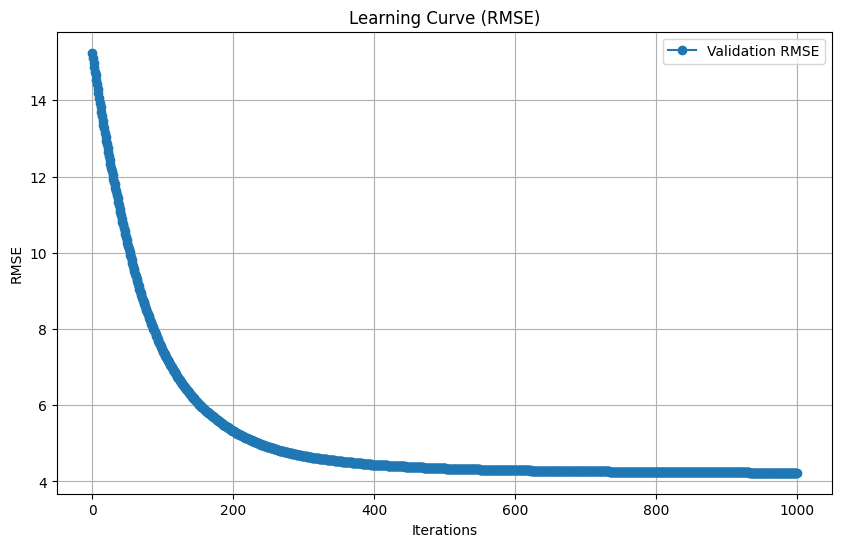

In [16]:
model.train_and_analyze()

In [17]:
# Assuming predictions and true labels are stored in these variables
y_train_pred = model.model.predict(model.X_train)
y_val_pred = model.model.predict(model.X_val)

# Call the display_metrics function
model.display_metrics(model.y_train, y_train_pred, model.y_val, y_val_pred)

Training Set Metrics:
  MAE: 2.8506
  MSE: 14.3872
  RMSE: 3.7930
  R²: 0.9480

Validation Set Metrics:
  MAE: 3.0207
  MSE: 17.8937
  RMSE: 4.2301
  R²: 0.9192


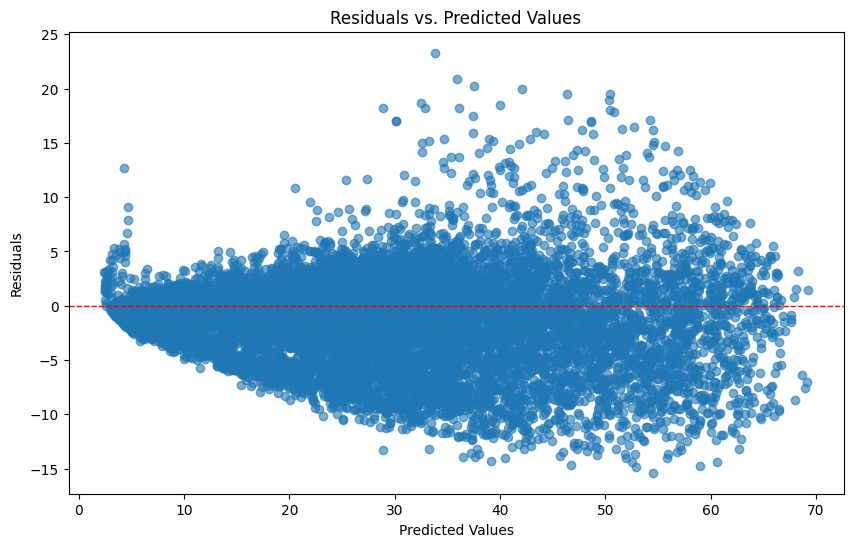

In [18]:
residuals = model.y_val.flatten() - y_val_pred.flatten()

# Scatter plot of residuals
plt.figure(figsize=(10, 6))
plt.scatter(y_val_pred, residuals, alpha=0.6)
plt.axhline(0, color='red', linestyle='--', linewidth=1)  # Reference line for zero residual
plt.title("Residuals vs. Predicted Values")
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.show();

In [10]:
model.save_model('model_lgb_25-67')

Model saved to c:\git\CampTvNew\notebooks\saved_models\model_lgb_25-67


In [ ]:
model.load_model()

Model loaded from c:\git\CampTvNew\notebooks\saved_models\best_model_lgb.pkl


### SHAP Visuals

In [ ]:
model.extract_and_visualize_shap_values(feature_dependence = 'timef_duration_days')

In [ ]:
# Log feature variance
print("Feature Variance:")
print(model.X_train.var())

# Log feature importance after training
print("Feature Importance:")
feature_importance = pd.DataFrame({
    'Feature': model.model.feature_name_,
    'Importance': model.model.feature_importances_,
}).sort_values(by='Importance', ascending=False)
print(feature_importance)

### Predictions

In [27]:
model.predict_and_export_to_excel(file_path="test_predictions_lgb_25-67.xlsx")

Using: <class 'lightgbm.basic.Booster'>
Test Set Metrics:
  MAE: 2.4408
  MSE: 11.5307
  RMSE: 3.3957
  R²: 0.9083


In [12]:
# Assuming predictions and true labels are stored in these variables
y_test_pred = model.model.predict(model.X_test)

# Training Metrics
test_mae = mean_absolute_error(model.y_test, y_test_pred)
test_mse = mean_squared_error(model.y_test, y_test_pred)
test_rmse = np.sqrt(test_mse)
test_r2 = r2_score(model.y_test, y_test_pred)

print(f"Test Metrics:")
print(f"Mean Absolute Error (MAE): {test_mae:.4f}")
print(f"Mean Squared Error (MSE): {test_mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {test_rmse:.4f}")
print(f"R-squared (R2): {test_r2:.4f}")

Test Metrics:
Mean Absolute Error (MAE): 2.4408
Mean Squared Error (MSE): 11.5307
Root Mean Squared Error (RMSE): 3.3957
R-squared (R2): 0.9083


## Catboost

In [20]:
from catboost import CatBoostRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Initialize CatBoost model
model_cat = CatBoostRegressor(
    iterations=4000,
    learning_rate=0.05,
    depth=12,
    l2_leaf_reg=2.0,
    loss_function='RMSE',
    verbose=100,
    early_stopping_rounds=400,
    colsample_bylevel=0.8,
    subsample = 1.0
)

# Train model
model_cat.fit(
    model.X_train, model.y_train,
    eval_set=(model.X_val, model.y_val),
    use_best_model=True
)

# Predict on test set
predictions = model_cat.predict(model.X_test)

# Evaluate
rmse = np.sqrt(mean_squared_error(model.y_test, predictions))
mae = mean_absolute_error(model.y_test, predictions)
r2 = r2_score(model.y_test, predictions)

print(f"Test RMSE: {rmse:.4f}")
print(f"Test MAE: {mae:.4f}")
print(f"Test R²: {r2:.4f}")

0:	learn: 15.9237263	test: 14.7052745	best: 14.7052745 (0)	total: 58.5ms	remaining: 3m 54s
100:	learn: 3.8722828	test: 4.5019394	best: 4.5019394 (100)	total: 6.05s	remaining: 3m 53s
200:	learn: 3.5095030	test: 4.4250703	best: 4.4250703 (200)	total: 12s	remaining: 3m 47s
300:	learn: 3.2457369	test: 4.4346292	best: 4.4194854 (238)	total: 18s	remaining: 3m 40s
400:	learn: 3.0208251	test: 4.4606403	best: 4.4194854 (238)	total: 25.3s	remaining: 3m 46s
500:	learn: 2.8352476	test: 4.4706156	best: 4.4194854 (238)	total: 33s	remaining: 3m 50s
600:	learn: 2.6887358	test: 4.4822593	best: 4.4194854 (238)	total: 41.1s	remaining: 3m 52s
Stopped by overfitting detector  (400 iterations wait)

bestTest = 4.419485387
bestIteration = 238

Shrink model to first 239 iterations.


Test RMSE: 3.3897
Test MAE: 2.4033
Test R²: 0.9086


In [21]:
def predict_and_export_to_excel(model_trained, model_catboost, file_path="test_predictions_cat.xlsx"):
    """
    Predicts on self.test_data and exports the results, including target, prediction, and residuals, to an Excel file.

    Parameters:
    - file_path (str): The path to save the Excel file. Default is "test_predictions.xlsx".
    """
    print("Using:", type(model_catboost))
    df_test = model_trained.test_data.copy()

    # Predict on the test set
    predictions = model_catboost.predict(model_trained.X_test)

    # Add predictions and residuals to the test dataframe
    df_test["prediction_cat"] = predictions
    df_test[model_trained.target] = model_trained.y_test.flatten()
    df_test["residual_cat"] = df_test[model_trained.target] - df_test["prediction_cat"]

    # Round the numerical values for better readability
    df_test[["prediction_cat", model_trained.target, "residual_cat"]] = df_test[["prediction_cat", model_trained.target, "residual_cat"]].round(2)

    # Select relevant columns
    df_test = df_test[[
        'flight_id', 'target_group', 'start_date', 'end_date', 'timef_duration_days', 'advertiser',
        'product', 'alcohol_kansspelen', 'npo1_grp_daynight',
        'npo1_grp_primetime', 'npo1_grp_total', 'npo2_grp_daynight',
        'npo2_grp_primetime', 'npo2_grp_total', 'npo3_grp_daynight',
        'npo3_grp_primetime', 'npo3_grp_total', 'regio_grp_daynight',
        'regio_grp_primetime', 'regio_grp_total', 'ster_grp_total',
        'ster_1+_total', 'prediction_cat', 'residual_cat'
    ]]

    # Calculate metrics
    test_mae = mean_absolute_error(model_trained.y_test, predictions)
    test_mse = mean_squared_error(model_trained.y_test, predictions)
    test_rmse = np.sqrt(test_mse)
    test_r2 = r2_score(model_trained.y_test, predictions)

    # Display Metrics
    print("Test Set Metrics:")
    print(f"  MAE: {test_mae:.4f}")
    print(f"  MSE: {test_mse:.4f}")
    print(f"  RMSE: {test_rmse:.4f}")
    print(f"  R²: {test_r2:.4f}")

    # Use the format_excel function to format and save the Excel file
    df_test.to_excel(file_path, index = False)

In [28]:
predict_and_export_to_excel(model, model_cat, file_path="test_predictions_cat_25-67.xlsx")

Using: <class 'catboost.core.CatBoostRegressor'>
Test Set Metrics:
  MAE: 2.4033
  MSE: 11.4901
  RMSE: 3.3897
  R²: 0.9086


In [ ]:
model_cat.save_model("./model_cat_boost_25-67")

In [24]:
# Assuming predictions and true labels are stored in these variables
y_train_pred = model_cat.predict(model.X_train)
y_val_pred = model_cat.predict(model.X_val)

# Call the display_metrics function
model.display_metrics(model.y_train, y_train_pred, model.y_val, y_val_pred)

Training Set Metrics:
  MAE: 2.5268
  MSE: 11.5856
  RMSE: 3.4038
  R²: 0.9582

Validation Set Metrics:
  MAE: 3.0829
  MSE: 19.5319
  RMSE: 4.4195
  R²: 0.9118


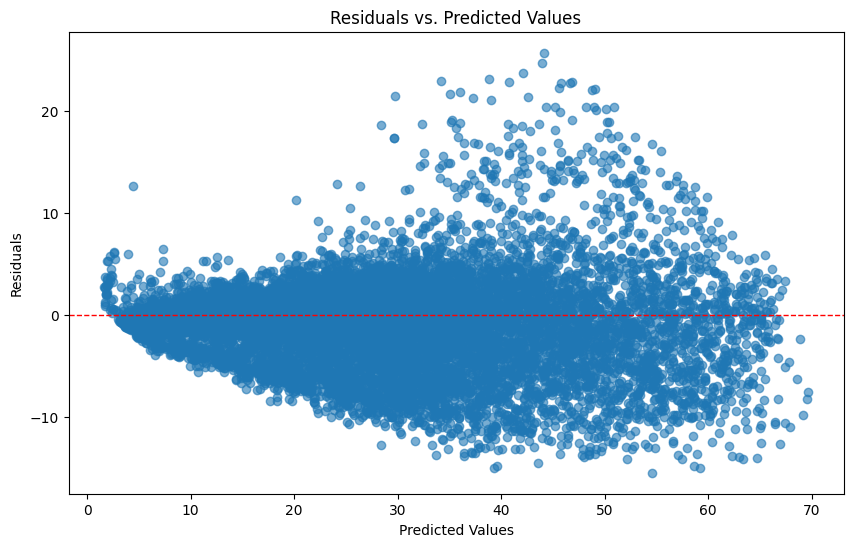

In [26]:
residuals = model.y_val.flatten() - y_val_pred.flatten()

# Scatter plot of residuals
plt.figure(figsize=(10, 6))
plt.scatter(y_val_pred, residuals, alpha=0.6)
plt.axhline(0, color='red', linestyle='--', linewidth=1)  # Reference line for zero residual
plt.title("Residuals vs. Predicted Values")
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.show();